<a href="https://colab.research.google.com/github/Ayushprajapati2006/BIS-LAB/blob/main/Ant_colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 0, Best Distance: 38
Iteration: 10, Best Distance: 28
Iteration: 20, Best Distance: 28
Iteration: 30, Best Distance: 28
Iteration: 40, Best Distance: 28
Iteration: 50, Best Distance: 28
Iteration: 60, Best Distance: 28
Iteration: 70, Best Distance: 28
Iteration: 80, Best Distance: 28
Iteration: 90, Best Distance: 28

Optimal Path Found:
[(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (2, 7), (3, 7), (4, 7), (4, 8), (5, 8), (6, 8), (6, 9), (7, 9), (8, 9), (8, 10), (8, 11), (8, 12), (8, 13), (9, 13), (9, 14), (10, 14), (11, 14), (12, 14), (13, 14), (14, 14)]

Total Path Distance: 28


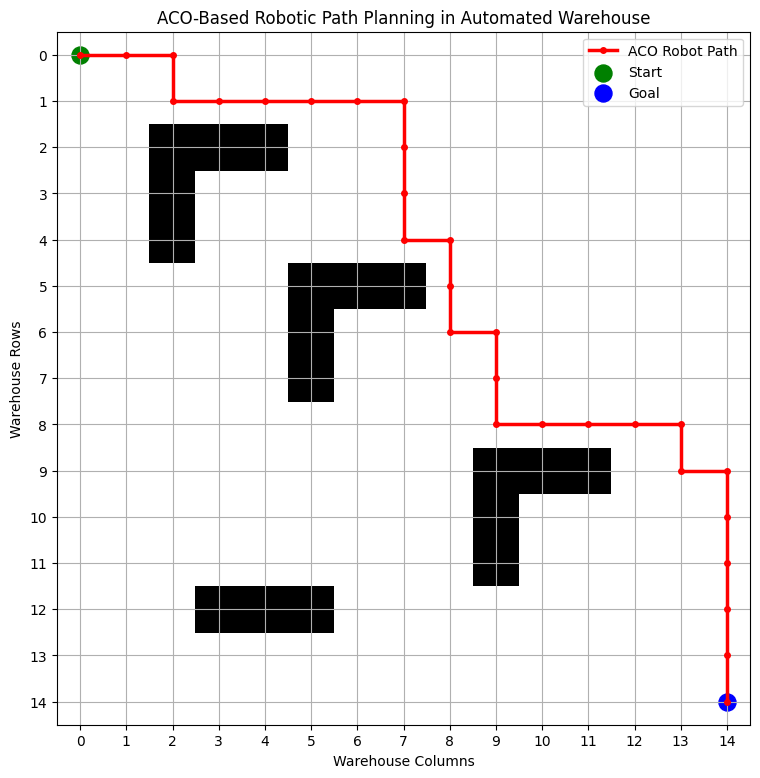

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import random



ROWS = 15
COLS = 15

START = (0, 0)
GOAL = (14, 14)


warehouse = np.zeros((ROWS, COLS))


obstacles = [
    (2, 2), (2, 3), (2, 4),
    (3, 2), (4, 2),
    (5, 5), (5, 6), (5, 7),
    (6, 5), (7, 5),
    (9, 9), (9, 10), (9, 11),
    (10, 9), (11, 9),
    (12, 3), (12, 4), (12, 5)
]

for obs in obstacles: warehouse[obs] = 1


NUM_ANTS = 30
ITERATIONS = 100

ALPHA = 1.0
BETA = 3.0
EVAPORATION = 0.5
Q = 100


pheromone = np.ones((ROWS, COLS))


MOVES = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]



def valid_moves(position, visited):

    neighbors = []

    r, c = position

    for dr, dc in MOVES:

        nr = r + dr
        nc = c + dc

        if (0 <= nr < ROWS and
            0 <= nc < COLS and
            warehouse[nr, nc] == 0 and
            (nr, nc) not in visited):

            neighbors.append((nr, nc))

    return neighbors




def heuristic(position):

    r, c = position
    gr, gc = GOAL

    distance = abs(gr-r) + abs(gc-c)

    return 1.0 / (distance + 1)



def select_next(current, neighbors):

    probabilities = []

    for neighbor in neighbors:

        r, c = neighbor

        tau = pheromone[r, c] ** ALPHA

        eta = heuristic(neighbor) ** BETA

        probabilities.append(tau * eta)

    probabilities = np.array(probabilities)

    probabilities /= probabilities.sum()

    index = np.random.choice(
        len(neighbors),
        p=probabilities
    )

    return neighbors[index]




def generate_path():

    current = START

    path = [START]

    visited = {START}

    max_steps = ROWS * COLS

    for _ in range(max_steps):

        if current == GOAL:
            return path

        neighbors = valid_moves(current, visited)

        if not neighbors:
            return None

        next_position = select_next(
            current,
            neighbors
        )

        path.append(next_position)

        visited.add(next_position)

        current = next_position

    return None




def update_pheromones(paths):

    global pheromone

    # Evaporation
    pheromone *= (1 - EVAPORATION)

    # Pheromone deposition
    for path in paths:

        if path is None:
            continue

        distance = len(path) - 1

        if distance == 0:
            continue

        deposit = Q / distance

        for position in path:

            r, c = position

            pheromone[r, c] += deposit




best_path = None
best_distance = float('inf')

for iteration in range(ITERATIONS):

    paths = []

    for ant in range(NUM_ANTS):

        path = generate_path()

        if path is not None:

            paths.append(path)

            distance = len(path) - 1

            if distance < best_distance:

                best_distance = distance
                best_path = path

    update_pheromones(paths)

    if iteration % 10 == 0:

        print(
            f"Iteration: {iteration}, "
            f"Best Distance: {best_distance}"
        )




if best_path is not None:

    print("\nOptimal Path Found:")
    print(best_path)

    print("\nTotal Path Distance:",
          best_distance)

    # Plot warehouse
    plt.figure(figsize=(9, 9))

    plt.imshow(
        warehouse,
        cmap='Greys',
        origin='upper'
    )

    # Extract path coordinates
    path_x = [p[1] for p in best_path]
    path_y = [p[0] for p in best_path]


    plt.plot(
        path_x,
        path_y,
        color='red',
        linewidth=2.5,
        marker='o',
        markersize=4,
        label='ACO Robot Path'
    )


    plt.scatter(
        START[1], START[0],
        color='green',
        s=150,
        label='Start'
    )

    plt.scatter(
        GOAL[1], GOAL[0],
        color='blue',
        s=150,
        label='Goal'
    )

    plt.title(
        "ACO-Based Robotic Path Planning "
        "in Automated Warehouse"
    )

    plt.xlabel("Warehouse Columns")
    plt.ylabel("Warehouse Rows")

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))

    plt.grid(True)
    plt.legend()

    plt.show()

else:

    print("No valid path found!")
